# 01 Data: pull, check and assemble the environmental dataset

**Purpose:** build one clean country-year dataset for 54 African countries plus global comparators, 1990 to the latest year, from the sources set out in `docs/Phase 1 Research Design.md`.

Every source is pulled live from its API or official download and saved in `data/raw/`, so the next run works offline if a site is down. Nothing is interpolated and a missing value is never written as zero.

| Source | What it gives | Access |
|---|---|---|
| World Bank (WDI, Sovereign ESG, WGI) | Emissions, energy, land, water, biodiversity, controls, governance | API |
| Our World in Data (Global Carbon Budget) | CO2 including land-use change | CSV on GitHub |
| Our World in Data (Ember, Energy Institute) | Electricity mix: solar, wind, hydro, fossil shares | CSV on GitHub |
| ND-GAIN, University of Notre Dame | Climate vulnerability and readiness | Zip download |
| UN SDG Global Database | Red List Index (SDG 15.5.1) | API |
| FAOSTAT | Cropland and agricultural land area | Zip download |

The indicator list, codes, units and limitations are in `config/indicator-catalogue.csv`.

In [1]:
import io
import json
import re
import urllib.parse
import urllib.request
import zipfile
from datetime import date, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

REFRESH = False          # True = download everything again; False = reuse files already in data/raw
DATA, RAW, CONFIG = Path("data"), Path("data/raw"), Path("config")
OUT = Path("outputs") / "01 data"
for p in (RAW, OUT):
    p.mkdir(parents=True, exist_ok=True)

catalogue = pd.read_csv(CONFIG / "indicator-catalogue.csv", dtype=str).fillna("")
countries = pd.read_csv(CONFIG / "countries.csv", dtype=str).fillna("")
SCOPE = set(countries["iso3"])
AFRICA = countries.loc[countries["group"] == "Africa", "iso3"].tolist()
print(f"{len(catalogue)} indicators in the catalogue; {len(AFRICA)} African countries and {len(SCOPE) - len(AFRICA)} comparators")

88 indicators in the catalogue; 54 African countries and 16 comparators


In [2]:
log = []      # one line per download: what, where from, when, how big


def fetch(url, cache, binary=False):
    """Download url into data/raw/<cache> unless it is already there (and REFRESH is off).
    If the site is unreachable, fall back to the saved copy."""
    path = RAW / cache
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and not REFRESH:
        status = "cached"
    else:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (research; Martin B. Mwaala)"})
            with urllib.request.urlopen(req, timeout=180) as r:
                path.write_bytes(r.read())
            status = "downloaded"
        except OSError as e:
            if not path.exists():
                raise
            status = f"offline, using saved copy ({e})"
    log.append({"file": cache, "url": url[:200], "status": status, "bytes": path.stat().st_size,
                "file_date": datetime.fromtimestamp(path.stat().st_mtime).strftime("%Y-%m-%d %H:%M")})
    return path.read_bytes() if binary else path.read_text(encoding="utf-8", errors="replace")


def keep(df):
    """Common clean-up: numeric values, years from 1990, countries in scope, missing dropped (never zero-filled)."""
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    df = df.dropna(subset=["iso3", "year", "value"])
    df["year"] = df["year"].astype(int)
    return df[df["iso3"].isin(SCOPE) & (df["year"] >= 1990)]

## 1. World Bank: WDI, Sovereign ESG and governance indicators

One API call per indicator for every economy, 1990 to today. I keep the World Bank's own definition and source organisation for the data dictionary, and its `lastupdated` date for each series.

In [3]:
def world_bank(code, source="2"):
    pages, page, rows, meta = 1, 1, [], {}
    while page <= pages:
        url = (f"https://api.worldbank.org/v2/country/all/indicator/{code}?format=json"
               f"&date=1990:{date.today().year}&per_page=20000&page={page}&source={source}")
        payload = json.loads(fetch(url, f"worldbank/{code} p{page}.json"))
        if "message" in payload[0]:
            raise ValueError(payload[0]["message"][0].get("value"))
        meta, pages = payload[0], int(payload[0]["pages"])
        rows += payload[1] or []
        page += 1
    info = json.loads(fetch(f"https://api.worldbank.org/v2/indicator/{code}?format=json&source={source}", f"worldbank/{code} meta.json"))
    definition = (info[1][0].get("sourceNote") or "").strip() if len(info) > 1 and info[1] else ""
    df = pd.DataFrame({"iso3": [r["countryiso3code"] for r in rows], "year": [r["date"] for r in rows],
                       "value": [r["value"] for r in rows], "flag": [r.get("obs_status") or "" for r in rows]})
    return keep(df), meta.get("lastupdated", ""), definition


wb_frames, wb_status, definitions = [], [], {}
for r in catalogue[catalogue["extractor"] == "worldbank"].itertuples():
    try:
        df, updated, definitions[r.indicator_id] = world_bank(r.wb_code, r.wb_source_id or "2")
        wb_frames.append(df.assign(indicator_id=r.indicator_id, source="World Bank"))
        wb_status.append([r.indicator_id, r.wb_code, "ok", len(df), df["iso3"].isin(AFRICA).groupby(df["iso3"]).any().sum(), updated])
    except Exception as e:
        wb_status.append([r.indicator_id, r.wb_code, f"failed: {e}", 0, 0, ""])

wb_status = pd.DataFrame(wb_status, columns=["indicator_id", "code", "status", "rows", "economies", "last_updated"])
print(wb_status["status"].str[:6].value_counts().to_string())
wb_status[wb_status["status"] != "ok"]

status
ok    60


,indicator_id,code,status,rows,economies,last_updated


In [4]:
# Country metadata from the World Bank: region and current income group
cl = json.loads(fetch("https://api.worldbank.org/v2/country?format=json&per_page=400", "worldbank/countries.json"))[1]
wb_country = pd.DataFrame([{"iso3": c["id"], "wb_name": c["name"], "wb_region": c["region"]["value"],
                            "income_group": c["incomeLevel"]["value"]} for c in cl])
wb_country.head()

,iso3,wb_name,wb_region,income_group
0,ABW,Aruba,Latin America & Caribbean,High income
1,AFE,Africa Eastern and Southern,Aggregates,Aggregates
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income
3,AFR,Africa,Aggregates,Aggregates
4,AFW,Africa Western and Central,Aggregates,Aggregates


## 2. Our World in Data: CO2 with land-use change, and the electricity mix

The World Bank's EDGAR emissions exclude land-use change. The Global Carbon Budget series (via OWID) adds it, which matters for Africa's forest economies. The electricity mix comes from Ember and the Energy Institute through OWID's energy dataset.

In [5]:
def owid(url, cache, extractor):
    data = pd.read_csv(io.StringIO(fetch(url, cache)))
    data = data[data["iso_code"].astype(str).str.len() == 3]          # drop OWID regional aggregates
    frames, status = [], []
    for r in catalogue[catalogue["extractor"] == extractor].itertuples():
        if r.series_key not in data:
            status.append([r.indicator_id, r.series_key, "column not in file"])
            continue
        df = data[["iso_code", "year", r.series_key]].rename(columns={"iso_code": "iso3", r.series_key: "value"})
        frames.append(keep(df).assign(indicator_id=r.indicator_id, source="Our World in Data", flag=""))
        status.append([r.indicator_id, r.series_key, "ok"])
    return frames, status


owid_frames, s1 = owid("https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv", "owid/owid-co2-data.csv", "owid_co2")
f2, s2 = owid("https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv", "owid/owid-energy-data.csv", "owid_energy")
owid_frames += f2
pd.DataFrame(s1 + s2, columns=["indicator_id", "column", "status"])

,indicator_id,column,status
0,A09,co2_including_luc_per_capita,ok
1,A10,land_use_change_co2,ok
2,B10E,renewables_share_elec,ok
3,B10A,solar_share_elec,ok
4,B10B,wind_share_elec,ok
5,B10C,hydro_share_elec,ok
6,B10D,fossil_share_elec,ok


## 3. ND-GAIN: climate vulnerability and readiness

ND-GAIN has no API. The download page links to a zip of CSV files, one per measure, with countries in rows and years in columns.

In [6]:
NDGAIN_PAGE = "https://gain.nd.edu/our-work/country-index/download-data/"
zip_path = RAW / "ndgain" / "ndgain.zip"
if REFRESH or not zip_path.exists():
    try:
        page = fetch(NDGAIN_PAGE, "ndgain/download page.html")
        link = re.findall(r'href="([^"]+\.zip)"', page)[0]
        link = link if link.startswith("http") else urllib.parse.urljoin(NDGAIN_PAGE, link)
        print("ND-GAIN zip:", link)
        fetch(link, "ndgain/ndgain.zip", binary=True)
    except (OSError, IndexError) as e:
        print("Could not download ND-GAIN automatically:", e)
        print("Download the zip from the ND-GAIN page and save it as data/raw/ndgain/ndgain.zip, then re-run.")

nd_frames, nd_status = [], []
if zip_path.exists():
    z = zipfile.ZipFile(zip_path)
    # main score files only: skip Mac metadata (__MACOSX), the trends folder and the per-indicator inputs
    csvs = {n.lower().rsplit("/", 1)[-1]: n for n in z.namelist()
            if n.lower().endswith(".csv") and "__macosx" not in n.lower() and "/trends/" not in n.lower() and "/indicators/" not in n.lower()}
    for r in catalogue[catalogue["extractor"] == "ndgain"].itertuples():
        f = csvs.get(f"{r.series_key}.csv")
        if f is None:
            nd_status.append([r.indicator_id, r.series_key, "file not in zip"])
            continue
        wide = pd.read_csv(z.open(f))
        iso = next(c for c in wide.columns if c.strip().upper() == "ISO3")
        years = [c for c in wide.columns if str(c).strip().isdigit()]
        df = wide.melt(id_vars=[iso], value_vars=years, var_name="year", value_name="value").rename(columns={iso: "iso3"})
        nd_frames.append(keep(df).assign(indicator_id=r.indicator_id, source="ND-GAIN", flag=""))
        nd_status.append([r.indicator_id, f, "ok"])
pd.DataFrame(nd_status, columns=["indicator_id", "file", "status"])

,indicator_id,file,status
0,F01,resources 2/gain/gain.csv,ok
1,F02,resources 2/vulnerability/vulnerability.csv,ok
2,F03,resources 2/readiness/readiness.csv,ok
3,F03A,resources 2/readiness/economic.csv,ok
4,F03B,resources 2/readiness/governance.csv,ok
5,F03C,resources 2/readiness/social.csv,ok
6,F04A,resources 2/vulnerability/exposure.csv,ok
7,F04B,resources 2/vulnerability/sensitivity.csv,ok
8,F04C,resources 2/vulnerability/capacity.csv,ok


## 4. UN SDG database: Red List Index

The Red List Index (SDG 15.5.1) is the biodiversity time series. The API reports countries by UN M49 numeric code, which I convert to ISO3.

In [7]:
import logging
import country_converter as coco
logging.getLogger("country_converter").setLevel(logging.ERROR)   # UN region codes (Africa, World, ...) have no ISO3: expected

sdg_frames = []
for r in catalogue[catalogue["extractor"] == "unsdg"].itertuples():
    url = f"https://unstats.un.org/sdgs/UNSDGAPIV5/v1/sdg/Series/Data?seriesCode={r.series_key}&pageSize=100000"
    data = pd.DataFrame(json.loads(fetch(url, f"unsdg/{r.series_key}.json")).get("data", []))
    codes = data["geoAreaCode"].astype(int).unique().tolist()
    m49 = dict(zip(codes, coco.convert(codes, src="UNcode", to="ISO3", not_found=None)))
    df = pd.DataFrame({"iso3": data["geoAreaCode"].astype(int).map(m49), "year": data["timePeriodStart"], "value": data["value"]})
    df = keep(df).drop_duplicates(["iso3", "year"])
    sdg_frames.append(df.assign(indicator_id=r.indicator_id, source="UN SDG Global Database", flag=""))
    print(r.indicator_id, r.series_key, len(df), "rows,", df["iso3"].isin(AFRICA).groupby(df["iso3"]).any().sum(), "economies")

E08 ER_RSK_LST 2196 rows, 54 economies


## 5. FAOSTAT: cropland and agricultural land

FAO bulk files carry a flag for each value (A official, E estimated, I imputed, X from another agency). I keep the flag so estimated values can be filtered later.

In [8]:
fao_frames = []
fao_zip = fetch("https://bulks-faostat.fao.org/production/Inputs_LandUse_E_All_Data_(Normalized).zip", "faostat/land use.zip", binary=True)
z = zipfile.ZipFile(io.BytesIO(fao_zip))
main = next(n for n in z.namelist() if n.lower().endswith(".csv") and "normalized" in n.lower() and "flag" not in n.lower())
fao = pd.read_csv(z.open(main), encoding="latin1", low_memory=False)
m49_col = next(c for c in fao.columns if "M49" in c)
codes = fao[m49_col].astype(str).str.lstrip("'").astype(int)
lookup = dict(zip(codes.unique(), coco.convert(codes.unique().tolist(), src="UNcode", to="ISO3", not_found=None)))
fao["iso3"] = codes.map(lookup)
for r in catalogue[catalogue["extractor"] == "faostat_rl"].itertuples():
    item, element = r.series_key.split("|")
    sub = fao[(fao["Item"] == item) & (fao["Element"] == element)]
    df = keep(pd.DataFrame({"iso3": sub["iso3"], "year": sub["Year"], "value": sub["Value"], "flag": sub.get("Flag", "").fillna("")}))
    fao_frames.append(df.assign(indicator_id=r.indicator_id, source="FAOSTAT"))
    print(r.indicator_id, item, element, len(df), "rows; flags:", df["flag"].value_counts().to_dict())

C11A Cropland Area 2085 rows; flags: {'I': 1750, 'A': 335}
C11B Agricultural land Area 2085 rows; flags: {'I': 1868, 'A': 217}


## 6. Combine into one long table

One row per country, year and indicator. Indicators in the catalogue that need an API key or a manual file (Global Forest Watch, IRENA, CCKP, IUCN, FRA 2025) are listed as not pulled.

In [9]:
obs = pd.concat(wb_frames + owid_frames + nd_frames + sdg_frames + fao_frames, ignore_index=True)
dups = obs.duplicated(["iso3", "year", "indicator_id"], keep="first").sum()
obs = obs.drop_duplicates(["iso3", "year", "indicator_id"], keep="first")
obs = obs[["iso3", "year", "indicator_id", "value", "source", "flag"]].sort_values(["indicator_id", "iso3", "year"])
obs.to_csv(DATA / "observations.csv", index=False)

pulled = set(obs["indicator_id"])
not_pulled = catalogue.loc[~catalogue["indicator_id"].isin(pulled), ["indicator_id", "indicator_name", "source", "access_method"]]
print(f"{len(obs):,} observations, {len(pulled)} indicators, {obs['iso3'].nunique()} economies; {dups} duplicate rows removed")
print(f"{len(not_pulled)} catalogue indicators not pulled:")
not_pulled

141,686 observations, 79 indicators, 66 economies; 0 duplicate rows removed
9 catalogue indicators not pulled:


,indicator_id,indicator_name,source,access_method
67,B11A,Solar installed capacity,IRENA IRENASTAT,PxWeb API (no key)
68,B11B,Onshore wind installed capacity,IRENA IRENASTAT,PxWeb API (no key)
69,B11C,Renewable hydropower installed capacity,IRENA IRENASTAT,PxWeb API (no key)
70,C05,Tree cover loss at 30% canopy (GFW),Global Forest Watch (UMD),Data API (free key in .env)
71,C06A,Forest area (FRA 2025),FAO Global Forest Resources Assessment 2025,Manual CSV export from fra-data.fao.org into d...
72,C06B,Deforestation rate (FRA 2025),FAO Global Forest Resources Assessment 2025,Manual CSV export
76,E09,"Threatened species assessed (CR, EN, VU) by co...",IUCN Red List API v4,"REST API (token in .env, non-commercial)"
86,F06A,Observed annual mean temperature,World Bank CCKP (CRU TS 4.08),CCKP API (no key; URL pattern in config/source...
87,F06B,Observed annual precipitation,World Bank CCKP (CRU TS 4.08),CCKP API (no key)


## 7. How complete is the data for Africa?

Share of the 25 years from 2000 to 2024 with an observed value, by indicator and country. This decides what can go into panel models (80% or more), what supports only limited panel work (50% to 80%) and what is cross-section only.

In [10]:
o = obs[obs["iso3"].isin(AFRICA) & obs["year"].between(2000, 2024)]
cov = (o.groupby(["indicator_id", "iso3"])["year"].nunique() / 25 * 100).unstack().reindex(columns=AFRICA).fillna(0)
summary = pd.DataFrame({
    "countries_with_data": (cov > 0).sum(axis=1),
    "coverage_pct": cov.mean(axis=1),
    "latest_year": o.groupby("indicator_id")["year"].max(),
})
summary["verdict"] = np.select([summary["coverage_pct"] >= 80, summary["coverage_pct"] >= 50], ["Panel ready", "Limited panel"], "Cross-section or descriptive")
summary = catalogue.set_index("indicator_id")[["indicator_name"]].join(summary, how="right").sort_values("coverage_pct", ascending=False)
print(summary["verdict"].value_counts().to_string())
summary

verdict
Panel ready                     68
Cross-section or descriptive     8
Limited panel                    3


,indicator_name,countries_with_data,coverage_pct,latest_year,verdict
indicator_id,,,,,
A09,CO2 including land-use change per capita,54,100.000,2024,Panel ready
A10,CO2 from land-use change,54,100.000,2024,Panel ready
B08,Access to clean fuels and technologies for coo...,54,100.000,2024,Panel ready
E08,Red List Index (SDG 15.5.1),54,100.000,2024,Panel ready
G07,Urban population share,54,100.000,2024,Panel ready
...,...,...,...,...,...
E01,"Mammal species, threatened",54,8.000,2022,Cross-section or descriptive
E02,"Bird species, threatened",54,8.000,2022,Cross-section or descriptive
E03,"Fish species, threatened",54,8.000,2022,Cross-section or descriptive


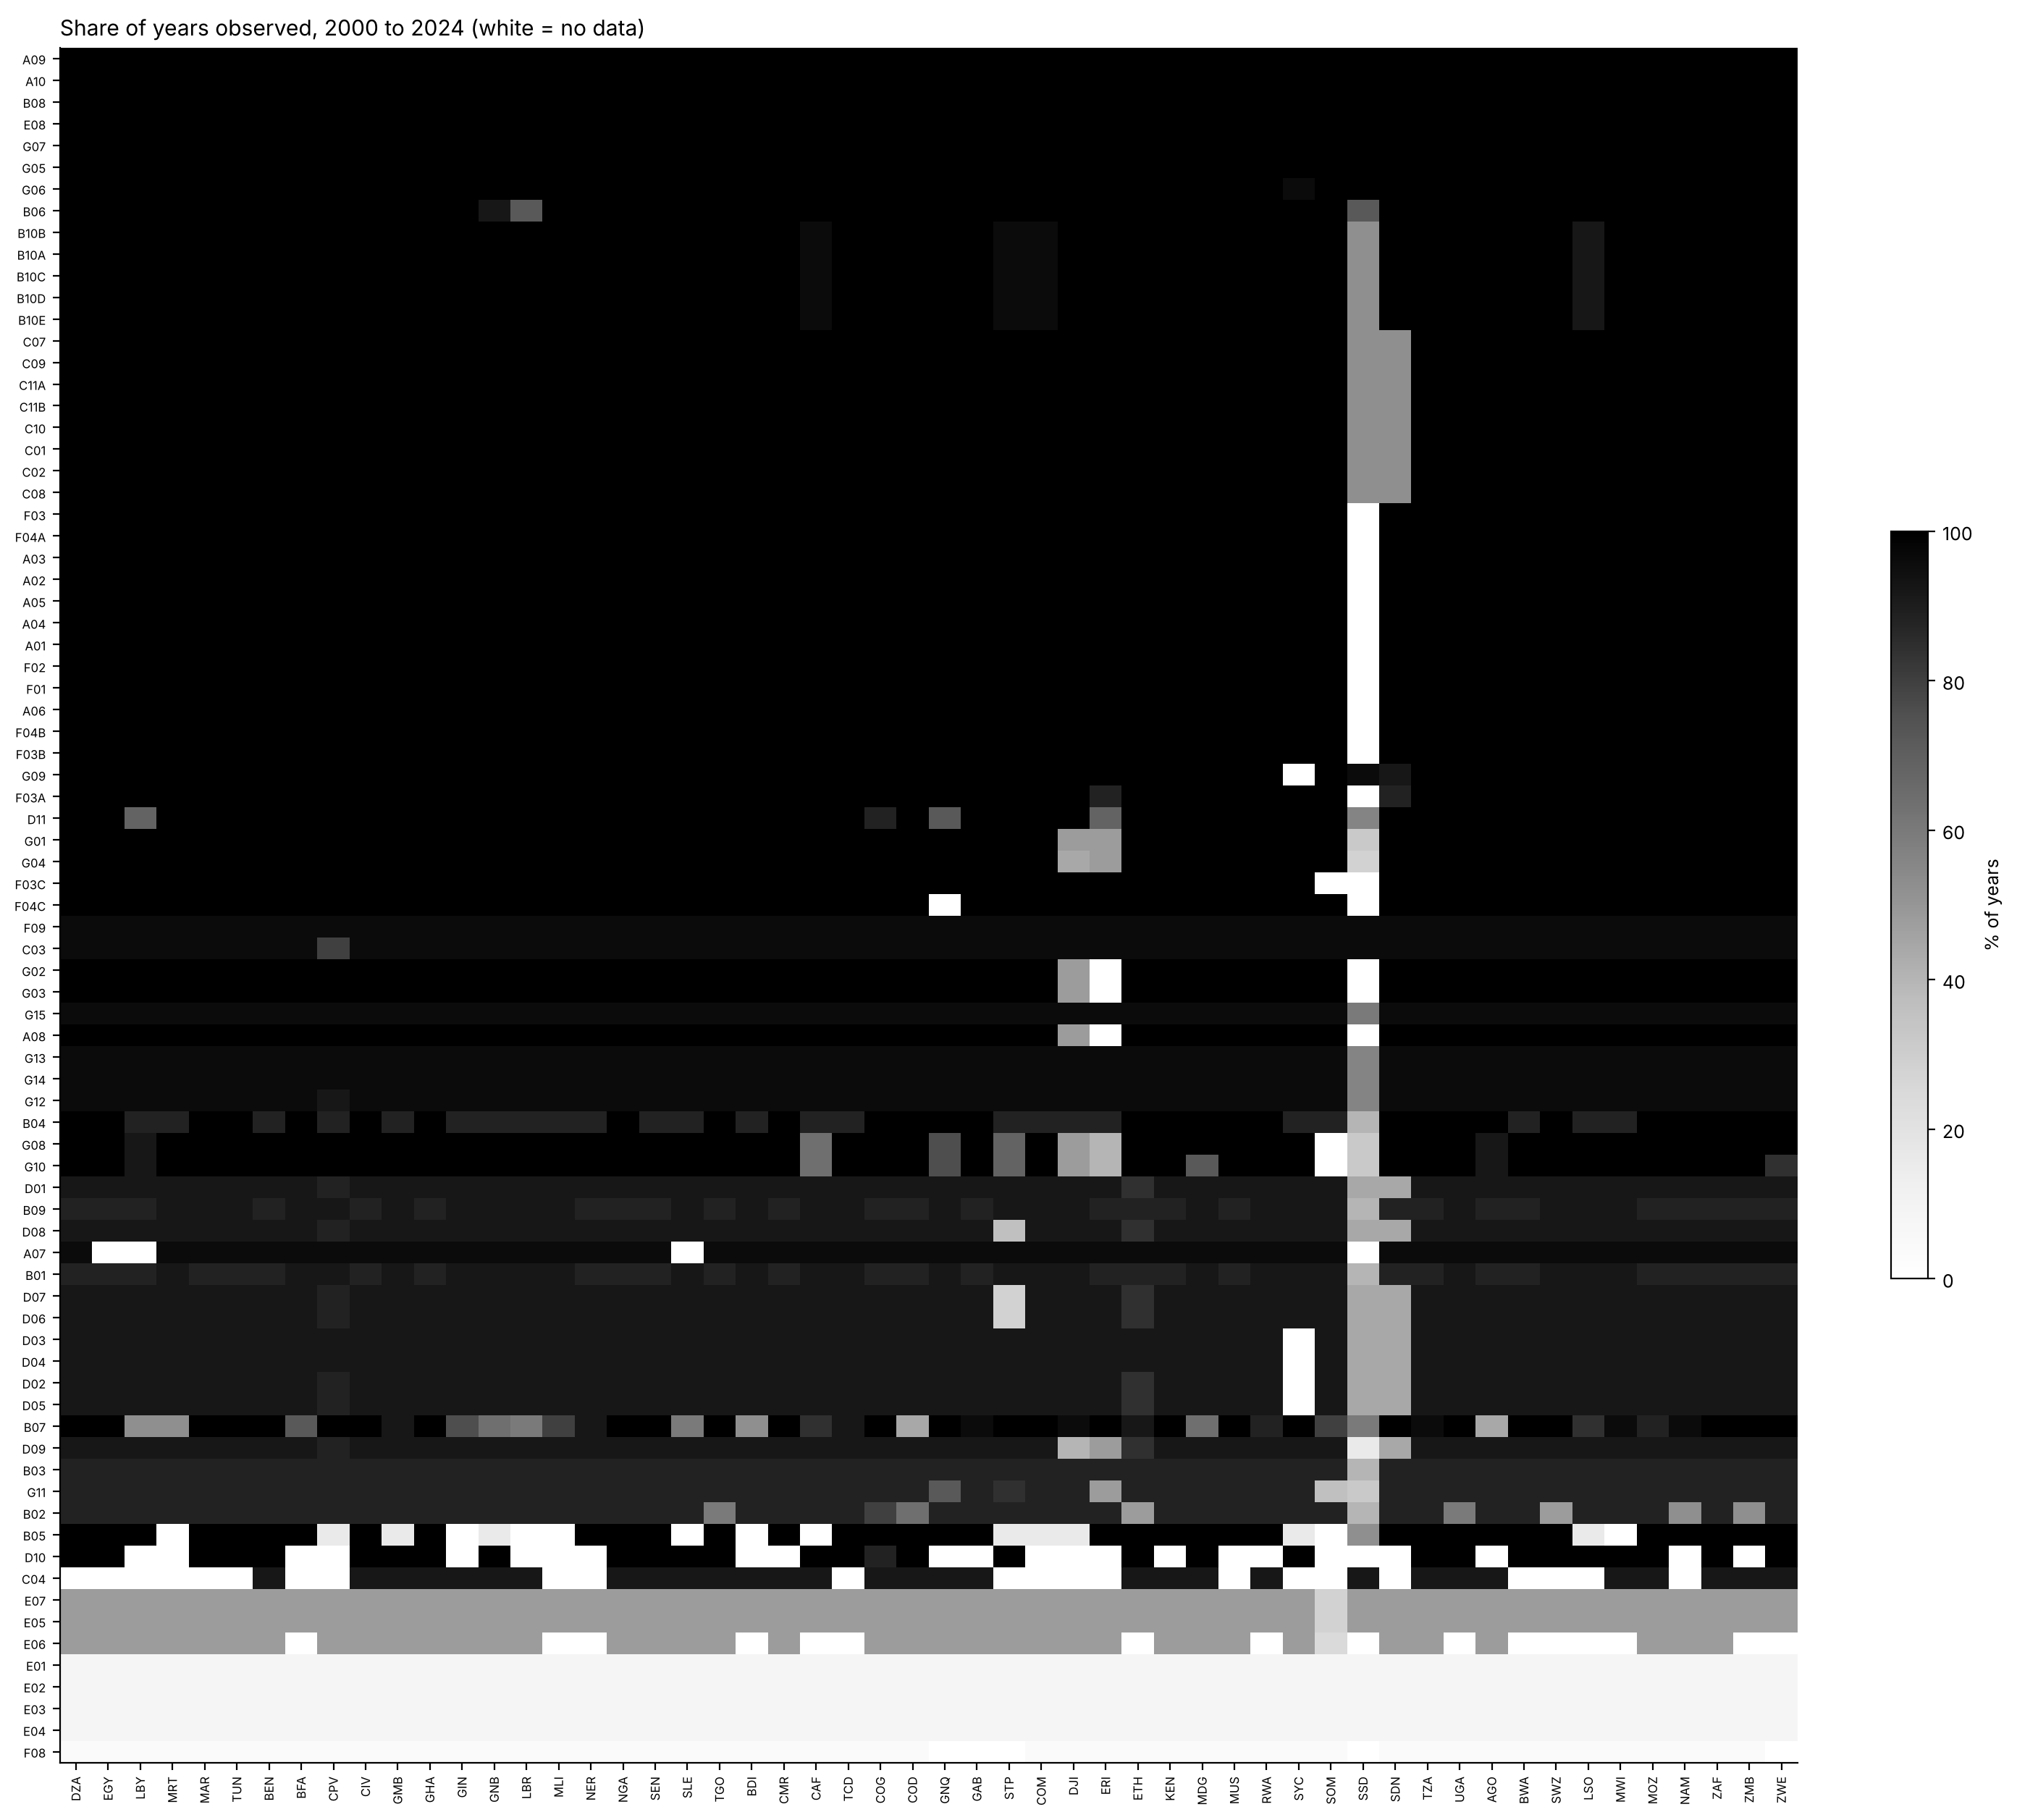

In [11]:
fig, ax = plt.subplots(figsize=(14, max(6, 0.16 * len(cov))))
im = ax.imshow(cov.loc[summary.index], aspect="auto", cmap="Greys", vmin=0, vmax=100)
ax.set_yticks(range(len(summary)), summary.index, fontsize=6)
ax.set_xticks(range(len(AFRICA)), AFRICA, rotation=90, fontsize=6)
ax.set_title("Share of years observed, 2000 to 2024 (white = no data)", loc="left"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.02, label="% of years")
fig.tight_layout(); fig.savefig(OUT / "coverage.png", dpi=150); plt.show()

**68 of the 79 indicators pulled are complete enough for panel work. Biodiversity, protected areas and disaster exposure are not.**

- The dataset holds 141,686 observations for 54 African countries and 12 comparator economies, from the World Bank, Our World in Data, ND-GAIN 2026, the UN SDG database and FAOSTAT.
- Below 50% coverage: threatened species counts (8%, a single snapshot year), disaster exposure (4%, one 1990 to 2009 average), marine protected areas (33%) and terrestrial protected areas (48%). These are used for cross-section comparisons only.
- Limited coverage: primary forest loss (53%, humid tropics only), safely managed drinking water (55%) and the legacy fossil fuel share (70%, discontinued).
- Nine catalogue indicators were not pulled because they need an API key or a manual export: IRENA capacity, Global Forest Watch, FRA 2025, IUCN counts and CCKP climate.
- The World Bank has renamed its governance indicators (`GE.EST` is now `GOV_WGI_GE.EST`). The catalogue is updated.

## 8. Quality checks

These flag values to review. They never change the data.

- **Suspected interpolation:** 4 or more consecutive years with an identical non-zero change. This is typical of values drawn in a straight line between survey years (FAO forest area is the known case).
- **Carried forward:** 4 or more consecutive identical values.
- **Year-on-year jump:** a change more than 5 robust standard deviations from that series' usual change.
- **Zero to review:** a zero where zero is implausible, such as GDP or population.
- **Series break:** Sudan in 2011, when South Sudan became independent.

In [12]:
ZERO_OK = ("B0", "B10", "B11", "C03", "C04", "C05", "C06B", "D0", "E0", "F08", "A10")   # zero is a real value here (e.g. no wind power yet)
flags = []


def runs(mask, n=3):
    out, start = np.zeros(len(mask), bool), None
    for i, m in enumerate(list(mask) + [False]):
        if m and start is None:
            start = i
        elif not m and start is not None:
            if i - start >= n:
                out[start:i] = True
            start = None
    return out


for (i, c), g in obs.groupby(["indicator_id", "iso3"]):
    g = g.sort_values("year")
    y, v = g["year"].to_numpy(), g["value"].to_numpy(float)
    if len(g) >= 5:
        consec = np.diff(y) == 1
        d = np.diff(v)
        scale = max(np.abs(v).max(), 1e-9)
        same = np.r_[False, np.isclose(d[1:], d[:-1], rtol=1e-6, atol=1e-9 * scale) & consec[1:] & consec[:-1]]
        for mask, kind in ((runs(same & (np.abs(d) > 1e-12 * scale)), "suspected interpolation"),
                           (runs((np.abs(d) <= 1e-12 * scale) & consec), "carried forward")):
            flags += [(c, int(yy), i, kind) for yy in y[np.where(mask)[0] + 1]]
        dd = d[consec]
        if len(dd) >= 5:
            mad = np.median(np.abs(dd - np.median(dd))) * 1.4826
            if mad > 0:
                flags += [(c, int(yy), i, "year-on-year jump") for yy in y[1:][consec][np.abs(dd - np.median(dd)) / mad > 5]]
    if not i.startswith(ZERO_OK):
        flags += [(c, int(yy), i, "zero to review") for yy in g.loc[g["value"] == 0, "year"]]
flags += [("SDN", 2011, i, "series break") for i in obs.loc[(obs["iso3"] == "SDN") & (obs["year"] == 2011), "indicator_id"]]

flags = pd.DataFrame(flags, columns=["iso3", "year", "indicator_id", "flag"])
flags.to_csv(DATA / "quality flags.csv", index=False)
qa = flags[flags["iso3"].isin(AFRICA)].pivot_table(index="indicator_id", columns="flag", values="year", aggfunc="count").fillna(0).astype(int)
qa.sort_values(qa.columns.tolist(), ascending=False).head(25)

flag,carried forward,series break,suspected interpolation,year-on-year jump,zero to review
indicator_id,,,,,
C10,1725,0,0,5,0
D03,1646,0,0,0,0
F04A,1537,1,0,0,0
B10B,1102,1,0,16,0
B10A,875,1,0,76,0
D07,665,0,0,90,0
D01,659,0,598,81,0
D06,644,0,0,78,0
D08,644,0,0,73,0


**The quality checks confirm the Phase 1 warnings: FAO forest and AQUASTAT water series are largely drawn in straight lines between survey years.**

- Suspected interpolation: 3,826 African country-years, concentrated in forest area (C01 and C02, 44 countries), water stress and withdrawals (D01, D02, D05) and clean cooking (B08).
- 17,174 values are carried forward unchanged for 4 or more years. Most are land area, renewable water resources and ND-GAIN exposure, all of which are fixed by design.
- FAOSTAT flags 1,750 of 2,085 cropland values as imputed (I) rather than official (A).
- Only 6 implausible zeros remain to review once genuine zeros (such as no wind power) are excluded.
- What this means for the analysis: annual changes in forest and water data are not treated as real movements, and these series are not forecast.

## 9. Build the country-year panel and the indicator dictionary

Two derived series are added, each with its formula recorded:

- **X01, CO2 intensity of GDP (in-house):** CO2 (A02, Mt) divided by GDP at constant PPP (G03). I recompute it so the numerator and denominator come from the same vintage. It is cross-checked against the World Bank's own A08.
- **X02, tree cover loss relative to forest area:** satellite tree cover loss (C03, ha) as a percentage of FAO forest area (C02, km² × 100). The two use different definitions, so treat it as a relative pressure signal, not a deforestation rate.

In [13]:
panel = obs.pivot_table(index=["iso3", "year"], columns="indicator_id", values="value", aggfunc="first").reset_index()
if {"A02", "G03"} <= set(panel):
    panel["X01"] = panel["A02"] * 1e9 / panel["G03"]
if {"C03", "C02"} <= set(panel):
    panel["X02"] = panel["C03"] / (panel["C02"] * 100) * 100

cty = countries.merge(wb_country, on="iso3", how="left")
agg = cty["group"] == "Comparator aggregate"
cty["country_name"] = cty["notes"].where(agg, coco.convert(cty["iso3"].tolist(), to="name_short", not_found=None))
cty["country_name"] = cty["country_name"].fillna(cty["wb_name"]).fillna(cty["iso3"])
cty[["iso3", "country_name", "group", "au_region", "wb_region", "income_group", "landlocked", "notes"]].to_csv(DATA / "countries.csv", index=False)
panel = panel.merge(cty[["iso3", "country_name", "au_region", "income_group"]], on="iso3", how="left")
panel.to_csv(DATA / "panel.csv", index=False)

derived = pd.DataFrame([
    {"indicator_id": "X01", "dimension": "A Carbon emissions and climate change", "indicator_name": "CO2 intensity of GDP (in-house)",
     "unit": "kg CO2e per 2021 PPP $", "source": "Derived: A02 * 1e9 / G03", "role": "Derived", "polarity": -1,
     "key_limitations": "Compare with A08; inherits EDGAR and GDP limitations"},
    {"indicator_id": "X02", "dimension": "C Deforestation and forest resources", "indicator_name": "Tree cover loss relative to forest area",
     "unit": "% of FAO forest area", "source": "Derived: C03 / (C02 * 100) * 100", "role": "Derived", "polarity": -1,
     "key_limitations": "Satellite loss over FAO forest area: different definitions; a relative pressure signal only"}])
indicators = pd.concat([catalogue, derived], ignore_index=True)
indicators["definition"] = indicators["indicator_id"].map(definitions).fillna(indicators["definition"] if "definition" in indicators else "")
cover = obs.groupby("indicator_id").agg(first_year=("year", "min"), last_year=("year", "max"), economies=("iso3", "nunique"))
indicators = indicators.merge(cover, on="indicator_id", how="left")
indicators.to_csv(DATA / "indicators.csv", index=False)
print(f"Panel: {len(panel):,} country-years x {panel.shape[1]} columns; dictionary: {len(indicators)} indicators")

Panel: 2,376 country-years x 86 columns; dictionary: 90 indicators


## 10. Save the data summary

In [14]:
from openpyxl.styles import Font

with pd.ExcelWriter(OUT / "data summary.xlsx", engine="openpyxl") as xl:
    summary.to_excel(xl, sheet_name="Coverage summary")
    cov.round(0).to_excel(xl, sheet_name="Coverage by country")
    qa.to_excel(xl, sheet_name="Quality flags")
    wb_status.to_excel(xl, sheet_name="World Bank status", index=False)
    not_pulled.to_excel(xl, sheet_name="Not pulled", index=False)
    indicators.to_excel(xl, sheet_name="Data dictionary", index=False)
    pd.DataFrame(log).to_excel(xl, sheet_name="Download log", index=False)
    for ws in xl.book.worksheets:
        ws.sheet_view.showGridLines = False
        ws.freeze_panes = "B2"
        for row in ws.iter_rows():
            for c in row:
                c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
sorted(p.name for p in DATA.iterdir()), sorted(p.name for p in OUT.iterdir())

(['clusters.csv',
  'countries.csv',
  'forecasts.csv',
  'indicators.csv',
  'observations.csv',
  'panel.csv',
  'quality flags.csv',
  'raw'],
 ['coverage.png', 'data summary.xlsx'])